Install the project dependencies once in the notebook environment with `pip install -r requirements.txt` if imports are missing. `sentencepiece` is required for the BPE tokenizer.


# Interpolated trigram language model
Train a smoothed trigram on the same preprocessed corpus used by the neural models. Compare validation and test perplexity, and inspect generated text.

In [2]:
# Set paths and add src/ so this notebook uses the same implementation as the scripts.
from pathlib import Path
import sys, json, math, time
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data' / 'processed_3m_max_tokens_30k_vocab'
print('Project:', ROOT)

Project: /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13


In [15]:
# Fit the trigram baseline on training IDs; time fitting and evaluate validation/test perplexity.
from ngram import InterpolatedTrigram
vocab = json.loads((DATA/'vocab.json').read_text())
ids = {s: json.loads((DATA/f'{s}.json').read_text()) for s in ('train','validation','test')}
model = InterpolatedTrigram(len(vocab), weights=(0.1,0.3,0.6), alpha=0.1)
t0=time.perf_counter(); model.fit(ids['train']); train_seconds=time.perf_counter()-t0
print('Train seconds:', round(train_seconds,3))
print('Validation PPL:', round(model.evaluate(ids['validation']),2))
print('Test PPL:', round(model.evaluate(ids['test']),2))

Train seconds: 1.93
Validation PPL: 1280.45
Test PPL: 1334.35


## Generation
Sampling is reproducible. This implementation samples over the full vocabulary and is intentionally simple; for long outputs, optimize it.

In [16]:
# Autoregressively sample one token at a time from the trigram next-token distribution.
import numpy as np
rng=np.random.default_rng(42)
stoi={w:i for i,w in enumerate(vocab)}
def generate_trigram(prompt, new_tokens=25, temperature=1.0):
    import sentencepiece as spm
    processor=spm.SentencePieceProcessor(model_file=str(DATA/'tokenizer.model'))
    history=processor.encode(prompt, out_type=int)
    history=([processor.eos_id()]*2+history)[-max(2,len(history)):]
    generated=[]
    for _ in range(new_tokens):
        a,b=history[-2:]
        probs=np.array([model.prob(a,b,c) for c in range(len(vocab))],dtype=float)
        probs=np.power(probs,1.0/temperature); probs/=probs.sum()
        token=int(rng.choice(len(vocab),p=probs))
        if token==processor.eos_id(): break
        history.append(token); generated.append(token)
    return processor.decode(generated)
for prompt in ['the scientist', 'the government']:
    print(prompt, '=>', generate_trigram(prompt))

the scientist => prussia moritzptides hungry what; danes nachtigall characters swift downstream jayma sequels staring gel fung phoenician @.@isia pia plow preft deepwater punished
the government => killed mechanism ' capital overview netherland overflowed updated grammaranyanisher hol competitors keats barron triv vacations arisingko shortlistabbing speculation ministry arromanchessu


In [17]:
# Save baseline training time and held-out perplexities for the report.
RESULTS = ROOT/'results'; RESULTS.mkdir(exist_ok=True)
record={'model':'trigram','train_seconds':train_seconds,'validation_ppl':model.evaluate(ids['validation']),'test_ppl':model.evaluate(ids['test']),'vocab_size':len(vocab)}
(RESULTS/'trigram.json').write_text(json.dumps(record,indent=2))
print('Saved', RESULTS/'trigram.json')

Saved /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/results/trigram.json


## Interpretation prompts
What does interpolation contribute relative to unsmoothed trigrams? How repetitive are generated continuations? **Fairness caveat:** this trigram evaluation skips the first two tokens, whereas the current neural evaluator scores from token 2; align scored positions before final report.

# RNN, LSTM and causal Transformer

In [1]:
# Resolve the project root and processed-data folder used by all later cells.
from pathlib import Path
import sys, json, math, time
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data' / 'processed_3m_max_tokens_30k_vocab'
print('Project:', ROOT)

Project: /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13


In [2]:
# Count subword token IDs separately from the next-token prediction targets.
import pandas as pd
split_ids = {name: json.loads((DATA / f"{name}.json").read_text()) for name in ("train", "validation", "test")}
split_counts = {name: len(ids) for name, ids in split_ids.items()}
metadata = json.loads((DATA / "metadata.json").read_text())
train_targets_per_epoch = max(0, split_counts["train"] - 1)
print("Subword token IDs in the saved splits:")
for name, count in split_counts.items():
    print(f"  {name:10} {count:>10,}")
print("\nNext-token prediction targets:")
print(f"  train per full epoch: {train_targets_per_epoch:,} (IDs minus the first context token)")
print(f"  validation: {split_counts['validation'] - 1:,} (IDs minus the first context token)")
print(f"  common test: {split_counts['test'] - 2:,} (positions 2 onward; two initial IDs provide context for the trigram)")
if "train_source_tokens_before_cap" in metadata:
    print(f"\nSource subword tokens before cap: {metadata['train_source_tokens_before_cap']:,}")
    print(f"Nonempty lines selected: {metadata['train_source_lines_selected']:,} / {metadata['train_nonempty_source_lines']:,}")

# Count presentations across the actual epochs, separately from unique corpus tokens.
exposures = []
for kind in ("rnn", "lstm", "transformer"):
    config_path = ROOT / "runs" / "revised" / kind / "config.json"
    history_path = ROOT / "runs" / "revised" / kind / "history.csv"
    if history_path.exists():
        history = pd.read_csv(history_path)
        count = int(history["train_tokens"].sum())
        basis = f"recorded over {len(history)} epochs"
    elif config_path.exists():
        config = json.loads(config_path.read_text())
        count = train_targets_per_epoch * int(config["epochs"])
        basis = f"configured estimate ({config['epochs']} epochs)"
    else:
        continue
    exposures.append({"model": kind, "training target tokens": count, "basis": basis})
if exposures:
    display(pd.DataFrame(exposures))
else:
    print("Full-run configs not found; at 10 epochs, each model would process ", f"{train_targets_per_epoch * 10:,} target tokens.", sep="")

Token IDs in processed splits:
  train        2,224,073
  validation     239,175
  test           272,269

Training corpus: 2,224,073 token IDs
Next-token targets per full epoch: 2,224,072
Validation next-token targets: 239,174
Common test targets (positions 2 onward): 272,267
Test evaluation starts at position 2 to provide two preceding tokens for the trigram.
Source subword tokens before cap: 2,224,073
Nonempty lines selected: 23,767 / 23,767


model,training target tokens,basis
rnn,22240720,recorded over 10 epochs
lstm,26688864,recorded over 12 epochs
transformer,26688864,recorded over 12 epochs


In [6]:
# Select MPS when available, then show the parameter counts for the three neural architectures.
import torch, subprocess, pandas as pd, matplotlib.pyplot as plt
from models import build_model
DEVICE='mps' if torch.backends.mps.is_available() else 'cpu'
print('PyTorch:',torch.__version__,'device:',DEVICE)
VOCAB_SIZE=len(json.loads((DATA/'vocab.json').read_text()))
for kind in ('rnn','lstm','transformer'):
    m=build_model(kind,VOCAB_SIZE,emb=100,hidden=128,heads=4,layers=2)
    print(kind, f'{sum(p.numel() for p in m.parameters()):,} parameters')

PyTorch: 2.14.1 device: mps
rnn 6,899,440 parameters
lstm 6,987,760 parameters
transformer 7,312,240 parameters


## 1. Short hardware benchmark
A 100-batch run on your own M2 gives a much more reliable time estimate than generic hardware estimates. These cells run only when enabled.

In [4]:
# Optional quick pilot: train on only 100 batches per split to catch setup problems.
RUN_PILOTS = False  # optional pilot; the full replacement run below is enabled
if RUN_PILOTS:
    for kind in ('rnn','lstm','transformer'):
        cmd=[sys.executable,str(ROOT/'src'/'train.py'),'--model',kind,'--data',str(DATA),'--out',str(ROOT/'runs'/'pilot'),'--epochs','1','--max-batches','100','--device',DEVICE]
        subprocess.run(cmd,check=True)

## 2. Full training

The runs use a 25-epoch maximum, 32-token context, and batch size 32, with early stopping after 5 consecutive epochs without validation-loss improvement. The best validation checkpoint is restored for evaluation.

The final test metrics printed by `train.py` are its chunked test pass (272,268 targets, including the first target position). Use the common-evaluation table below for the report comparison: it evaluates the same 272,267 targets for every model and reports rolling and chunk-matched context separately. The chunk-matched score should be close to the train-script score; rolling perplexity is lower because each prediction can use the preceding test-stream context.

Train each model only once unless a run fails.

In [ ]:
RUN_FULL = True  # replace the existing Part I checkpoints using the new tokenizer
if RUN_FULL:
    for kind in ('rnn','lstm','transformer'):
        cmd=[sys.executable,str(ROOT/'src'/'train.py'),'--model',kind,'--data',str(DATA),'--out',str(ROOT/'runs'/'revised'),'--epochs','25','--patience','5','--context','32','--batch-size','32','--seed','42','--device',DEVICE]
        subprocess.run(cmd,check=True)

{"epoch": 1, "train_loss": 6.540116864531222, "val_loss": 6.23472098422114, "val_ppl": 510.15825638533727, "train_seconds": 185.78, "seconds": 192.45, "train_tokens": 2224072, "val_tokens": 239174, "best_epoch": 1, "epochs_without_improvement": 0}
{"epoch": 2, "train_loss": 5.849774054868224, "val_loss": 6.022760587050917, "val_ppl": 412.7163640000822, "train_seconds": 200.66, "seconds": 208.49, "train_tokens": 2224072, "val_tokens": 239174, "best_epoch": 2, "epochs_without_improvement": 0}
{"epoch": 3, "train_loss": 5.5639747518035, "val_loss": 5.943671733427288, "val_ppl": 381.3325135269041, "train_seconds": 201.61, "seconds": 208.89, "train_tokens": 2224072, "val_tokens": 239174, "best_epoch": 3, "epochs_without_improvement": 0}
{"epoch": 4, "train_loss": 5.373943378129572, "val_loss": 5.902334934766757, "val_ppl": 365.89080239275177, "train_seconds": 196.02, "seconds": 202.85, "train_tokens": 2224072, "val_tokens": 239174, "best_epoch": 4, "epochs_without_improvement": 0}
{"epoch":

## 3. Compare training curves
Plots appear once training has produced `history.csv` files.

/Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/results/revised_loss_curves.png


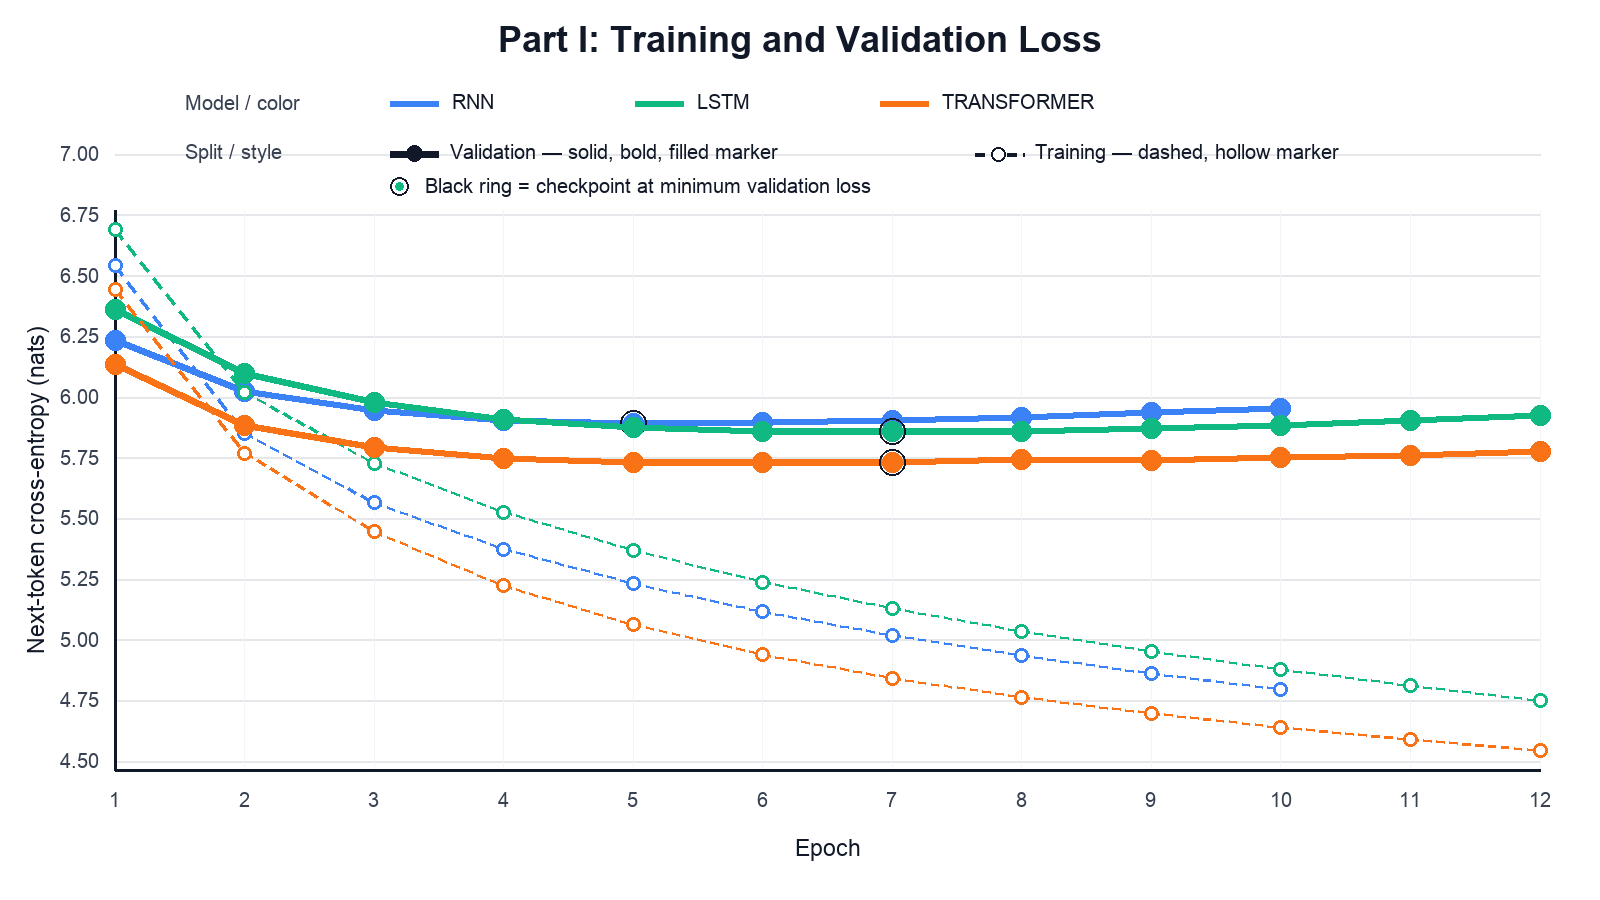

In [7]:
# Rebuild and display the exact saved training-curve image embedded in the report.
run_root = ROOT / "runs" / "revised"
curve_path = ROOT / "results" / "revised_loss_curves.png"
subprocess.run([sys.executable, str(ROOT / "src" / "plot_part1_curves.py"),
                "--runs", str(run_root), "--out", str(curve_path)], check=True)
from IPython.display import Image as DisplayImage, display
display(DisplayImage(filename=str(curve_path)))

## 4. Common-evaluation result summary

The comparison table below reads `results/revised_common_evaluation.json`, the same shared-target evaluation used in the report. The per-model `runs/revised/<model>/results.json` files are training-time test passes with a different target-window setup; do not use those values as the final cross-model comparison.


In [12]:
# Use the common evaluation artifact used by the report, not each training script's separate test pass.
common_path = ROOT / "results" / "revised_common_evaluation.json"
if common_path.exists():
    common = json.loads(common_path.read_text())
    history_root = ROOT / "runs" / "revised"
    rows = []
    for kind, result in common["models"].items():
        chunk = result.get("context_comparisons", {}).get("chunk_matched_32", {})
        history_path = history_root / kind / "history.csv"
        best_epoch = "—"
        if history_path.exists():
            history = pd.read_csv(history_path)
            best_epoch = int(history.loc[history.val_loss.idxmin(), "epoch"])
        timing = result.get("timing", {})
        size = result["serialized_size_bytes"] / 1_000_000
        model_size = result.get("parameters", result.get("stored_unigrams", 0) + result.get("stored_bigrams", 0) + result.get("stored_trigrams", 0))
        rows.append({"model": kind, "test CE": result["test_loss"], "rolling PPL": result["test_ppl"],
                     "chunk-matched PPL": chunk.get("test_ppl", float("nan")),
                     "test targets": result["test_tokens"], "parameters / stored entries": model_size,
                     "artifact MB": size, "train seconds": result.get("training_seconds"),
                     "forward tokens/s": timing.get("forward_tokens_per_second"),
                     "end-to-end tokens/s": timing.get("end_to_end_tokens_per_second"),
                     "best validation epoch": best_epoch})
    display(pd.DataFrame(rows).set_index("model").round(3))
else:
    print("Run the common reporting cell first.")

,test CE,rolling PPL,chunk-matched PPL,test targets,parameters / stored entries,artifact MB,train seconds,forward tokens/s,end-to-end tokens/s,best validation epoch
model,,,,,,,,,,
rnn,5.887,360.417,371.521,272267,6899440,27.601,2173.770,30233.896,17570.257,5
lstm,5.858,350.010,362.724,272267,6987760,27.954,2413.230,21208.547,20747.001,7
transformer,5.686,294.603,319.232,272267,7312240,29.258,2462.590,12285.111,13163.849,7
trigram,7.196,1334.350,NaN,272267,2236087,26.777,1.443,694019.644,710838.446,—


### Possible architectural explanations for the Part I results

Part I primarily compares the n-gram, RNN, LSTM, and Transformer model families. A plausible explanation for the Transformer’s lower test loss is that causal self-attention can directly combine information from any earlier position in its 32-token window. The RNN and LSTM pass information through a recurrent state, while the trigram uses only the previous two tokens. This architectural difference may help the Transformer use longer-range context. The Transformer’s advantage is not proof that attention alone caused the improvement: it has 4.6% more parameters than the LSTM and trained slightly longer. See [Vaswani et al. (2017)](https://arxiv.org/abs/1706.03762).

The LSTM’s small advantage over the vanilla RNN (PPL 350.01 versus 360.42) may come from its gates, which regulate what information is retained or updated across steps [Hochreiter and Schmidhuber (1997)](https://doi.org/10.1162/neco.1997.9.8.1735). The difference is modest and comes from one seed, so it does not establish that gating alone explains the result. The trigram’s much higher perplexity is plausible given its two-token history and sparse counts over 30,000 subword pieces, despite smoothing; its training time and throughput show the corresponding efficiency advantage.

The context ablation is supplementary evidence: with only two preceding tokens, the Transformer–LSTM perplexity gap narrows from 55.41 to 3.74. This is consistent with the Transformer benefiting more from the full context window in this run. Separately, the neural loss curves show overfitting after the validation minimum: training loss continues to fall while validation loss rises. Repeated passes over about 2.22 million training subwords and model capacity may contribute, though this experiment does not isolate those factors.

Finally, the weak generated continuations despite better perplexity are plausible because test perplexity scores one next token at a time, while free-running generation feeds sampled tokens back into the model, so early errors can compound. The few prompts shown are illustrative, not a systematic generation benchmark.

## 5. Common test evaluation and matched generation
The evaluation scores the same target positions for all four model families. It compares rolling 32-token context with chunk-matched contexts and a neural context-2 ablation. Repeated timing reports prebuilt forward-only and end-to-end throughput after warm-up. Generation uses shared prompts, length, temperature, top-k, and seed. Run after the new Part I checkpoints exist. The generator stops when it samples `<eos>`.

In [9]:
# Optional common reporting: evaluate all models on shared targets and generate matched samples.
RUN_COMMON_REPORTING = True  # run after the enabled full-training cell completes
if RUN_COMMON_REPORTING:
    subprocess.run([sys.executable,str(ROOT/'src'/'evaluate_common.py'),'--data',str(DATA),'--runs',str(ROOT/'runs'/'revised'),'--out',str(ROOT/'results'/'revised_common_evaluation.json'),'--timing-repeats','3'],check=True)
    subprocess.run([sys.executable,str(ROOT/'src'/'generate_compare.py'),'--data',str(DATA),'--runs',str(ROOT/'runs'/'revised'),'--out',str(ROOT/'results'/'revised_generation.json'),'--new-tokens','30','--temperature','0.8','--top-k','40','--seed','42'],check=True)
    subprocess.run([sys.executable,str(ROOT/'src'/'plot_part1_curves.py'),'--runs',str(ROOT/'runs'/'revised'),'--out',str(ROOT/'results'/'revised_loss_curves.png')],check=True)
    subprocess.run([sys.executable,str(ROOT/'src'/'update_part1_report.py')],check=True)

{
  "evaluation": "common targets at positions >= 2; rolling context is up to 32 preceding tokens",
  "device": "mps",
  "hardware": {
    "system": "macOS-26.6.2-arm64-arm-64bit-Mach-O",
    "architecture": "arm64",
    "processor": "arm",
    "torch_version": "2.14.1",
    "device": "mps",
    "model": "Mac14,2",
    "chip": "Apple M2",
    "memory_bytes": 17179869184
  },
  "context": 32,
  "inference_batch_size": 128,
  "timing_repeats": 3,
  "context_comparison": "rolling full window versus chunk_matched train.py reset boundaries",
  "models": {
    "rnn": {
      "test_loss": 5.887261848522703,
      "test_ppl": 360.41705553653736,
      "test_tokens": 272267,
      "timing": {
        "forward_seconds_median": 9.00535612506792,
        "forward_tokens_per_second": 30233.895941338636,
        "end_to_end_seconds_median": 15.495902833063155,
        "end_to_end_tokens_per_second": 17570.257308213877,
        "repeats": 3,
        "warmup_batches": 1,
        "forward_scope": "preb

[WARNING] [makePDF] LaTeX Warning: Unused global option(s): [9pt].


### Review the common evaluation and continuations
The output uses subword decoding rather than joining BPE pieces with spaces.


In [10]:
# Display saved common-evaluation metrics, including device and platform metadata.
common_path=ROOT/'results'/'revised_common_evaluation.json'
if common_path.exists():
    common=json.loads(common_path.read_text())
    display(pd.DataFrame(common['models']).T)
    print('Device:',common['device'],'| Hardware:',common['hardware'])
else:
    print('Run the common reporting cell first.')

,test_loss,test_ppl,test_tokens,timing,inference_seconds,tokens_per_second,context_comparisons,parameters,serialized_size_bytes,serialized_artifact,training_hardware,training_seconds,training_time_basis,stored_unigrams,stored_bigrams,stored_trigrams
rnn,5.887262,360.417056,272267,"{'forward_seconds_median': 9.00535612506792, '...",15.495903,17570.257308,{'rolling_32': {'test_loss': 5.887261848522703...,6899440,27600554,/Users/paulng/Y4S1 Local files/DSA4213/dsa4213...,{'system': 'macOS-26.6.2-arm64-arm-64bit-Mach-...,2173.77,sum of synchronized train-epoch times; exclude...,NaN,NaN,NaN
lstm,5.857961,350.009842,272267,"{'forward_seconds_median': 12.837607666384429,...",13.123198,20747.000713,"{'rolling_32': {'test_loss': 5.85796127300001,...",6987760,27953834,/Users/paulng/Y4S1 Local files/DSA4213/dsa4213...,{'system': 'macOS-26.6.2-arm64-arm-64bit-Mach-...,2413.23,sum of synchronized train-epoch times; exclude...,NaN,NaN,NaN
transformer,5.685628,294.602763,272267,"{'forward_seconds_median': 22.162354874890298,...",20.682932,13163.849065,{'rolling_32': {'test_loss': 5.685627883014269...,7312240,29257693,/Users/paulng/Y4S1 Local files/DSA4213/dsa4213...,{'system': 'macOS-26.6.2-arm64-arm-64bit-Mach-...,2462.59,sum of synchronized train-epoch times; exclude...,NaN,NaN,NaN
trigram,7.196199,1334.349557,272267,"{'forward_seconds_median': 0.3923044577240944,...",0.383022,710838.446015,NaN,NaN,26776875,/Users/paulng/Y4S1 Local files/DSA4213/dsa4213...,NaN,1.442794,single fit on the training stream,28137,682945,1525005


Device: mps | Hardware: {'system': 'macOS-26.6.2-arm64-arm-64bit-Mach-O', 'architecture': 'arm64', 'processor': 'arm', 'torch_version': '2.14.1', 'device': 'mps', 'model': 'Mac14,2', 'chip': 'Apple M2', 'memory_bytes': 17179869184}


In [11]:
# Print each model’s continuation for each fixed prompt so outputs can be compared side by side.
generation_path=ROOT/'results'/'revised_generation.json'
if generation_path.exists():
    generation=json.loads(generation_path.read_text())
    for prompt_i in range(3):
        print('\nPrompt:',generation['continuations']['trigram'][prompt_i]['prompt'])
        for kind, samples in generation['continuations'].items():
            print(kind+':',samples[prompt_i]['continuation'])
else:
    print('Run the common reporting cell first.')


Prompt: The scientist studied
trigram: , when he is a in a similar to "
rnn: in order to become a new year with the club , though they were not in the same year . in the series , the church of scientology 's
lstm: in england and .
transformer: the languedoc as " a " a lion " and a.v. " the part of the city " , and the city 's third army ,

Prompt: The government announced
trigram: the song , the new zealand for the the end of the new , which was .
rnn: the area .
lstm: the team of the game 's final , but he could be a better to be a " perfect boy [ in love " and the songs of the
transformer: , " the most important parties that he was not to make the " big " .

Prompt: In the history of
trigram: , the episode of the second @-@ to , 's " .
rnn: the song " .
lstm: the time of the season .
transformer: the new kingdom .


## Which Part I model is best?

For **next-token prediction quality**, the Transformer is the best model in the revised common evaluation. All models were scored on the same 272,267 test targets with a 32-token context. Its test cross-entropy is 5.686 nats/token and perplexity is 294.6, compared with 5.858 and 350.0 for the LSTM. That is about a 2.9% lower cross-entropy and a 15.8% lower perplexity. The Transformer also leads in the chunk-boundary-matched comparison (perplexity 319.2 vs. 362.7 for the LSTM), so the ranking is not only caused by the rolling-context evaluation.

| Model | Test cross-entropy | Test perplexity | Train time | End-to-end test throughput | Parameters |
|---|---:|---:|---:|---:|---:|
| Transformer | 5.686 | **294.6** | 2,462.6 s | 13,164 tokens/s | 7.31 M |
| LSTM | 5.858 | 350.0 | **2,413.2 s** | **20,747 tokens/s** | 6.99 M |
| RNN | 5.887 | 360.4 | 2,173.8 s | 17,570 tokens/s | 6.90 M |

The Transformer is therefore the **best predictive model**, while the LSTM is the better speed-quality compromise: the Transformer is about 1.6 times slower at end-to-end inference and took about 2% longer to train than the LSTM. Their parameter counts are close (the Transformer has about 4.6% more). The Transformer’s final training loss is also lower than the LSTM’s, but training loss alone does not establish generalization; its validation loss reached its minimum at epoch 7 and then rose while training loss continued falling. Early stopping retained that best-validation checkpoint.

These are observed results from one training seed and one fixed setup. They support choosing the Transformer when test prediction quality is the priority, but do not establish that the architecture alone caused the difference. The models have similar parameter counts and share the data, context, and training procedure, yet the experiment does not include multiple seeds or uncertainty intervals. The trigram remains much faster, but its test perplexity is 1,334.3.